<a href="https://colab.research.google.com/github/alisa-maisara/heart-disease-prediction/blob/main/heart_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Data Preparation	                        	 	   			(20 marks)

  a)    Import the dataset: The dataset can be downloaded from Kaggle as follows


In [ ]:
# Start by importing the pandas library
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Use the pandas read_csv function to read the dataset
df = pd.read_csv('HeartDiseaseTrain-Test.csv')

In [ ]:
df.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholestoral,fasting_blood_sugar,rest_ecg,Max_heart_rate,exercise_induced_angina,oldpeak,slope,vessels_colored_by_flourosopy,thalassemia,target
0,52,Male,Typical angina,125,212,Lower than 120 mg/ml,ST-T wave abnormality,168,No,1.0,Downsloping,Two,Reversable Defect,0
1,53,Male,Typical angina,140,203,Greater than 120 mg/ml,Normal,155,Yes,3.1,Upsloping,Zero,Reversable Defect,0
2,70,Male,Typical angina,145,174,Lower than 120 mg/ml,ST-T wave abnormality,125,Yes,2.6,Upsloping,Zero,Reversable Defect,0
3,61,Male,Typical angina,148,203,Lower than 120 mg/ml,ST-T wave abnormality,161,No,0.0,Downsloping,One,Reversable Defect,0
4,62,Female,Typical angina,138,294,Greater than 120 mg/ml,ST-T wave abnormality,106,No,1.9,Flat,Three,Fixed Defect,0


  b) Handle missing values: If the dataset contains any missing values, these should be handled appropriately, either by removing rows or columns with missing values, or by filling in the missing values.

In [ ]:
# Check for missing values
print("\nMissing values before handling:")
print(df.isnull().sum())

# Example: Dropping rows with any missing values (common for clean datasets)
df_cleaned = df.dropna()
print("\nMissing values after dropping rows:")
print(df_cleaned.isnull().sum())

# If you wanted to fill missing values (e.g., with the mean for numerical columns):
# df_filled = df.fillna(df.mean(numeric_only=True))
# print("\nMissing values after filling with mean:")
# print(df_filled.isnull().sum())


Missing values before handling:
age                              0
sex                              0
chest_pain_type                  0
resting_blood_pressure           0
cholestoral                      0
fasting_blood_sugar              0
rest_ecg                         0
Max_heart_rate                   0
exercise_induced_angina          0
oldpeak                          0
slope                            0
vessels_colored_by_flourosopy    0
thalassemia                      0
target                           0
dtype: int64

Missing values after dropping rows:
age                              0
sex                              0
chest_pain_type                  0
resting_blood_pressure           0
cholestoral                      0
fasting_blood_sugar              0
rest_ecg                         0
Max_heart_rate                   0
exercise_induced_angina          0
oldpeak                          0
slope                            0
vessels_colored_by_flourosopy    0
thalass

  c)	Perform one-hot encoding for categorical features: Some features might be 			categorical and need to be converted into a numerical format. One common way to 		do this is by one-hot encoding.


In [ ]:
# Identify categorical columns (you'll need to inspect your dataset to confirm these)
# Common categorical columns in heart disease datasets might include:
# 'sex', 'cp' (chest pain type), 'fbs' (fasting blood sugar), 'restecg', 'exang', 'slope', 'ca', 'thal'
# For demonstration, let's assume 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal' are categorical.
# IMPORTANT: Adjust this list based on the actual categorical columns in your dataset!
# Based on the error and the dataframe head, the correct categorical columns are:
# 'sex', 'chest_pain_type', 'fasting_blood_sugar', 'rest_ecg', 'exercise_induced_angina', 'slope', 'vessels_colored_by_flourosopy', 'thalassemia'
categorical_cols = ['sex', 'chest_pain_type', 'fasting_blood_sugar', 'rest_ecg', 'exercise_induced_angina', 'slope', 'vessels_colored_by_flourosopy', 'thalassemia']

# Ensure all categorical columns exist in the DataFrame before encoding
# This check is still good practice even with the corrected list
cols_to_encode = [col for col in categorical_cols if col in df_cleaned.columns]
missing_cols = [col for col in categorical_cols if col not in df_cleaned.columns]

if missing_cols:
    print(f"Warning: Categorical columns {missing_cols} not found in the dataset. Skipping one-hot encoding for these columns.")

df_encoded = pd.get_dummies(df_cleaned, columns=cols_to_encode, drop_first=True) # drop_first to avoid multicollinearity
df_encoded.head()

,age,resting_blood_pressure,cholestoral,Max_heart_rate,oldpeak,target,sex_Male,chest_pain_type_Atypical angina,chest_pain_type_Non-anginal pain,chest_pain_type_Typical angina,...,exercise_induced_angina_Yes,slope_Flat,slope_Upsloping,vessels_colored_by_flourosopy_One,vessels_colored_by_flourosopy_Three,vessels_colored_by_flourosopy_Two,vessels_colored_by_flourosopy_Zero,thalassemia_No,thalassemia_Normal,thalassemia_Reversable Defect
0,52,125,212,168,1.0,0,True,False,False,True,...,False,False,False,False,False,True,False,False,False,True
1,53,140,203,155,3.1,0,True,False,False,True,...,True,False,True,False,False,False,True,False,False,True
2,70,145,174,125,2.6,0,True,False,False,True,...,True,False,True,False,False,False,True,False,False,True
3,61,148,203,161,0.0,0,True,False,False,True,...,False,False,False,True,False,False,False,False,False,True
4,62,138,294,106,1.9,0,False,False,False,True,...,False,True,False,False,True,False,False,False,False,False


d)	Split the data: The dataset should be split into features (X) and target variable (y), 		and then further split into training and test sets.

In [ ]:
from sklearn.model_selection import train_test_split

# Assuming 'target' is your target variable (predicting heart disease)
# IMPORTANT: Replace 'target' with the actual name of your target column in the dataset.
if 'target' in df_encoded.columns:
    X = df_encoded.drop('target', axis=1)
    y = df_encoded['target']
else:
    print("Error: 'target' column not found. Please verify the target column name in your dataset.")
    exit() # Or handle this error gracefully

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # stratify for balanced classes

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (820, 22)
X_test shape: (205, 22)
y_train shape: (820,)
y_test shape: (205,)


2.	Model Building 									   (15 marks)

  a)	Build a Neural Network model using scikit-learn's ‘MLPClassifier’ for this task. You 		can start with a simple architecture with one hidden layer.

In [ ]:
from sklearn.neural_network import MLPClassifier

# Initialize MLPClassifier with a simple architecture (one hidden layer)
# The 'hidden_layer_sizes' tuple defines the number of neurons in each hidden layer.
# (100,) means one hidden layer with 100 neurons.
# 'max_iter' is the maximum number of iterations (epochs) to run.
# 'random_state' for reproducibility.
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42, activation='relu', solver='adam')

print(mlp)

MLPClassifier(max_iter=500, random_state=42)


3.	Model Training 							   (15 marks)

  a)	Train your model using the training data.

In [ ]:
print("Training the model...")
mlp.fit(X_train, y_train)
print("Model training complete.")

Training the model...
Model training complete.


4.	Model Evaluation								   (20 marks)

  a)	Evaluate the performance of your model on the test data. Since this is a classification problem, you might want to use metrics such as accuracy, precision, recall, or F1 score.



Model Evaluation on Test Data:
Accuracy: 0.8683
Precision: 0.8679
Recall: 0.8762
F1-Score: 0.8720


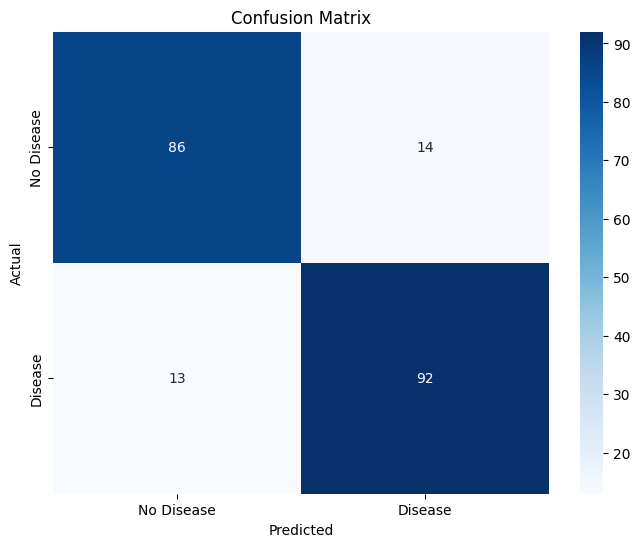

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Make predictions on the test data
y_pred = mlp.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"\nModel Evaluation on Test Data:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Confusion Matrix (for better understanding of performance)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

5.	Report 										   (15 marks)

  a)	Prepare a report detailing your methodology, findings, and any challenges you faced along the way. Be sure to include visualizations, such as plots of your data and results.

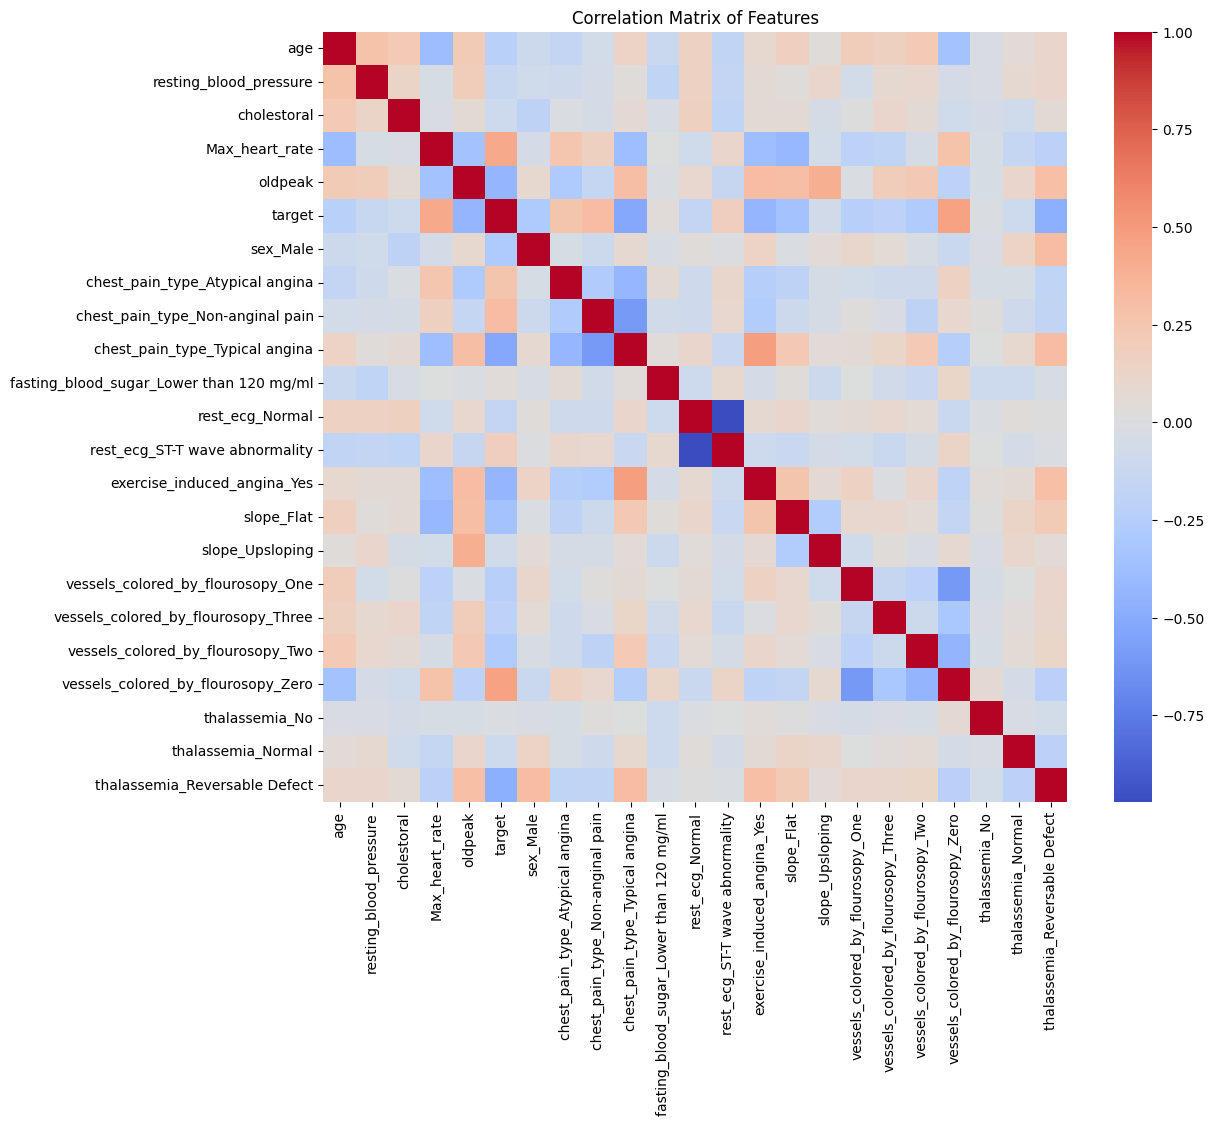

In [ ]:
# Correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(df_encoded.corr(), annot=False, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Features')
plt.show()

6.	Model Optimization						   (15 marks)

  a)	Try different architectures for your network (i.e., different numbers of layers and nodes per layer) and different training parameters to see if you can improve the performance of your model. Record the results of your different experiments and 		discuss why you think certain architectures or parameters worked better than others.

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Let's try a few simple architectures and parameters manually

# Experiment 1: One hidden layer with fewer neurons
print("\n--- Simple Experiment 1: One hidden layer (50 neurons) ---")
mlp_simple_exp1 = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=42, activation='relu', solver='adam')
mlp_simple_exp1.fit(X_train, y_train)
y_pred_simple_exp1 = mlp_simple_exp1.predict(X_test)
accuracy_simple_exp1 = accuracy_score(y_test, y_pred_simple_exp1)
print(f"Accuracy (Simple Exp 1): {accuracy_simple_exp1:.4f}")

# Experiment 2: Two hidden layers with a few neurons each
print("\n--- Simple Experiment 2: Two hidden layers (30, 30 neurons) ---")
mlp_simple_exp2 = MLPClassifier(hidden_layer_sizes=(30, 30), max_iter=500, random_state=42, activation='relu', solver='adam')
mlp_simple_exp2.fit(X_train, y_train)
y_pred_simple_exp2 = mlp_simple_exp2.predict(X_test)
accuracy_simple_exp2 = accuracy_score(y_test, y_pred_simple_exp2)
print(f"Accuracy (Simple Exp 2): {accuracy_simple_exp2:.4f}")

# Experiment 3: One hidden layer, more iterations
print("\n--- Simple Experiment 3: One hidden layer (100 neurons), more iterations (1000) ---")
mlp_simple_exp3 = MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42, activation='relu', solver='adam')
mlp_simple_exp3.fit(X_train, y_train)
y_pred_simple_exp3 = mlp_simple_exp3.predict(X_test)
accuracy_simple_exp3 = accuracy_score(y_test, y_pred_simple_exp3)
print(f"Accuracy (Simple Exp 3): {accuracy_simple_exp3:.4f}")

# You can add more simple experiments here


--- Simple Experiment 1: One hidden layer (50 neurons) ---
Accuracy (Simple Exp 1): 0.8634

--- Simple Experiment 2: Two hidden layers (30, 30 neurons) ---
Accuracy (Simple Exp 2): 0.8829

--- Simple Experiment 3: One hidden layer (100 neurons), more iterations (1000) ---
Accuracy (Simple Exp 3): 0.8683
